# Prelude

In [1]:
%cd /home/mfixman/TP/MyPyCop

/home/mfixman/Dropbox/continuous/TP/MyPyCop


In [2]:
import pandas
import scipy
import numpy
import matplotlib
import seaborn
import json
import glob

from matplotlib import pyplot

from pandas import Series, DataFrame

In [3]:
seaborn.set()

# Getting Data

In [4]:
%pwd

'/home/mfixman/Dropbox/continuous/TP/MyPyCop'

In [5]:
data = pandas.concat(
    [
        pandas.read_csv(
            'results/sat_guided.csv',
        ),
        pandas.read_csv(
          'results/SYN.csv',
        )
    ],
    ignore_index = True,
).drop_duplicates(['problem', 'strategy'])

In [6]:
strategies = data.strategy.unique()
strategies

array(['FirstAction', 'LeanCopCut', 'SATSolve', 'SATSolveGuided',
       'SATSolveGuidedProbeConflicts', 'SATSolveGuidedForcedTrue',
       'SATSolveGuidedEVSIDS', 'SATSolveGuidedShort',
       'SATSolveGuidedFast', 'SATSolveLiteral'], dtype=object)

In [7]:
# problems = data.xs(level = 'strategy', key = 'SATSolveGuided').index.str[:3].unique()
# data = data[data.index.get_level_values('problem').str[:3].isin(problems)]
# problems

In [8]:
# data = data.groupby(level = 'problem').filter(lambda x: x.solved.count() == len(strategies))

In [9]:
data.problem.str[:3].unique()

array(['AGT', 'ALG', 'ANA', 'BOO', 'CAT', 'COL', 'COM', 'CSR', 'FLD',
       'GEO', 'GRA', 'GRP', 'HEN', 'HWV', 'KLE', 'KRS', 'LAT', 'LCL',
       'LDA', 'MED', 'MGT', 'NLP', 'NUM', 'PLA', 'PRO', 'PUZ', 'REL',
       'RNG', 'SCT', 'SET', 'SEU', 'SEV', 'SWB', 'SWC', 'SWV', 'SWW',
       'SYN', 'SYO', 'TOP', 'HAL', 'MSC', 'ROB', 'BIO', 'NUN', 'HWC',
       'PHI'], dtype=object)

# Analysing

In [10]:
control = ['FirstAction', 'LeanCopCut']

In [11]:
data[data.solved]

,problem,strategy,status,solved,steps,time_ms,info,error
0,AGT002+2.p,FirstAction,solved,True,172.0,333.0,Theorem,NaN
1,AGT002+2.p,LeanCopCut,solved,True,172.0,334.0,Theorem,NaN
2,AGT002+2.p,SATSolve,solved,True,0.0,0.0,Theorem (SAT),NaN
3,AGT002+2.p,SATSolveGuided,solved,True,0.0,0.0,Theorem (SAT),NaN
4,AGT002+2.p,SATSolveGuidedProbeConflicts,solved,True,0.0,0.0,Theorem (SAT),NaN
...,...,...,...,...,...,...,...,...
24205,SYN981+1.p,SATSolveGuidedForcedTrue,solved,True,13.0,2.0,Theorem (SAT),NaN
24206,SYN981+1.p,SATSolveGuidedEVSIDS,solved,True,13.0,1.0,Theorem (SAT),NaN
24207,SYN981+1.p,SATSolveGuidedShort,solved,True,13.0,1.0,Theorem (SAT),NaN
24208,SYN981+1.p,SATSolveGuidedFast,solved,True,13.0,1.0,Theorem (SAT),NaN


In [12]:
data[data.solved].groupby('strategy').size()

strategy
FirstAction                     585
LeanCopCut                      616
SATSolve                        576
SATSolveGuided                  560
SATSolveGuidedEVSIDS            578
SATSolveGuidedFast              575
SATSolveGuidedForcedTrue        568
SATSolveGuidedProbeConflicts    563
SATSolveGuidedShort             587
SATSolveLiteral                 551
dtype: int64

In [13]:
data.groupby(['problem', 'strategy']).filter(lambda x: x.status.count() > 1)

,problem,strategy,status,solved,steps,time_ms,info,error


In [14]:
solved = data.pivot(columns = 'strategy', values = 'solved')

In [15]:
solved[solved.sum(axis = 1) == 1].sum(axis = 0)

strategy
FirstAction                     585
LeanCopCut                      616
SATSolve                        576
SATSolveGuided                  560
SATSolveGuidedEVSIDS            578
SATSolveGuidedFast              575
SATSolveGuidedForcedTrue        568
SATSolveGuidedProbeConflicts    563
SATSolveGuidedShort             587
SATSolveLiteral                 551
dtype: object

# Results

<Axes: xlabel='strategy'>

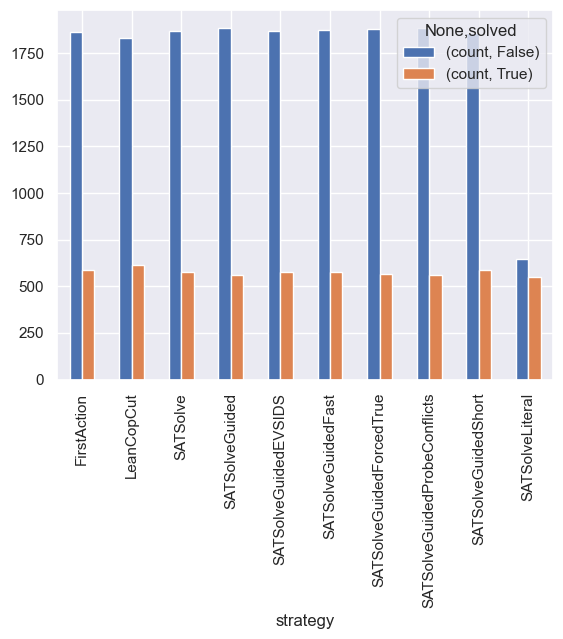

In [16]:
data.groupby('strategy').solved.value_counts().to_frame().reset_index('solved').pivot(columns = 'solved').plot.bar()

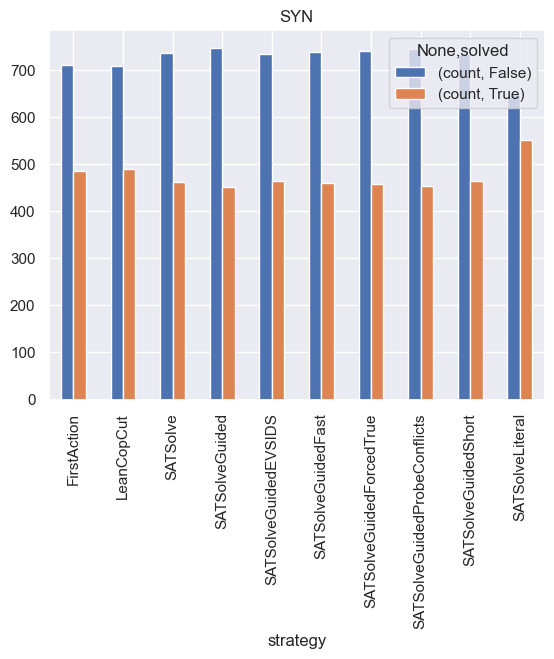

In [17]:
data[data.problem.str[:3] == 'SYN'].groupby('strategy').solved.value_counts().to_frame().reset_index('solved').pivot(columns = 'solved').plot.bar()
pyplot.title('SYN')
None

<Axes: xlabel='winner', ylabel='loser'>

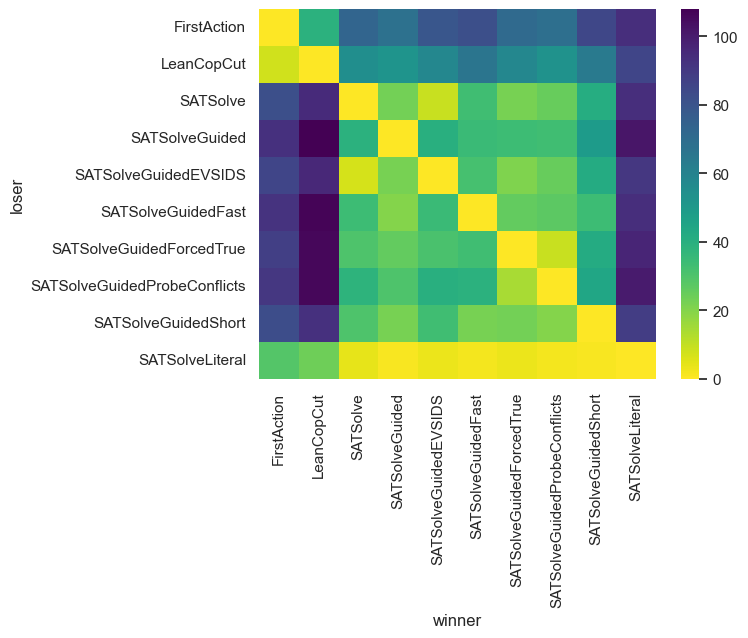

In [18]:
merged = pandas.merge(
    data,
    data,
    left_on = 'problem',
    right_on = 'problem',
    suffixes = ('_left', '_right'),
)

# merged = merged[merged.strategy_left < merged.strategy_right]
results = (
    merged
    [~merged.solved_left & merged.solved_right]
    [['strategy_left', 'strategy_right']]
    .value_counts()
    .unstack(level = 'strategy_right', fill_value = 0)
    .rename_axis(index = 'loser', columns = 'winner')
)

seaborn.heatmap(results, cmap = 'viridis_r')

In [32]:
results[cols].loc[cols.rename('')]

winner,SATSolve,SATSolveGuided,SATSolveGuidedEVSIDS,SATSolveGuidedFast,SATSolveGuidedForcedTrue,SATSolveGuidedProbeConflicts,SATSolveGuidedShort,SATSolveLiteral
,,,,,,,,
SATSolve,0,23,9,33,22,25,41,94
SATSolveGuided,39,0,40,35,34,33,49,102
SATSolveGuidedEVSIDS,7,22,0,32,21,25,42,91
SATSolveGuidedFast,34,20,35,0,26,27,34,94
SATSolveGuidedForcedTrue,30,26,31,33,0,9,42,97
SATSolveGuidedProbeConflicts,38,30,40,39,14,0,44,100
SATSolveGuidedShort,30,22,33,22,23,20,0,89
SATSolveLiteral,4,1,3,2,3,2,1,0


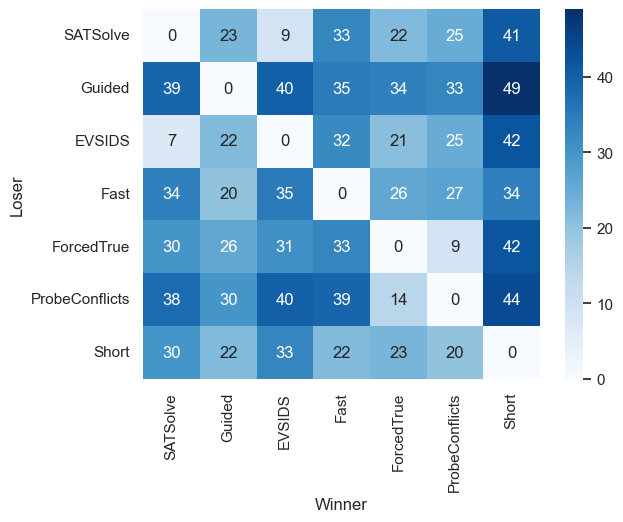

In [67]:
cols = results.columns[results.columns.str.startswith('SAT') & ~results.columns.str.endswith('Literal')]
plot = (
    results.
    loc[cols, cols].
    rename_axis(index = 'Loser', columns = 'Winner').
    rename(index = lambda x: x.removeprefix('SATSolveGuided') if x != 'SATSolveGuided' else 'Guided').
    rename(columns = lambda x: x.removeprefix('SATSolveGuided') if x != 'SATSolveGuided' else 'Guided')
)

seaborn.heatmap(
    plot,
    annot = plot,
    cmap = 'Blues',
)
# pyplot.title('Winners and losers of different SAT policies. Subset of 1458 problems.')
pyplot.savefig('figures/sat_policies_plot.png', bbox_inches = 'tight')

In [72]:
data

,problem,strategy,status,solved,steps,time_ms,info,error
0,AGT002+2.p,FirstAction,solved,True,172.0,333.0,Theorem,NaN
1,AGT002+2.p,LeanCopCut,solved,True,172.0,334.0,Theorem,NaN
2,AGT002+2.p,SATSolve,solved,True,0.0,0.0,Theorem (SAT),NaN
3,AGT002+2.p,SATSolveGuided,solved,True,0.0,0.0,Theorem (SAT),NaN
4,AGT002+2.p,SATSolveGuidedProbeConflicts,solved,True,0.0,0.0,Theorem (SAT),NaN
...,...,...,...,...,...,...,...,...
24205,SYN981+1.p,SATSolveGuidedForcedTrue,solved,True,13.0,2.0,Theorem (SAT),NaN
24206,SYN981+1.p,SATSolveGuidedEVSIDS,solved,True,13.0,1.0,Theorem (SAT),NaN
24207,SYN981+1.p,SATSolveGuidedShort,solved,True,13.0,1.0,Theorem (SAT),NaN
24208,SYN981+1.p,SATSolveGuidedFast,solved,True,13.0,1.0,Theorem (SAT),NaN


In [87]:
pandas.concat(
    [
        merged[(merged.strategy_left == 'SATSolve') & (merged.strategy_right == x) & ~merged.solved_left & merged.solved_right].sample(2)
        for x in cols if x != 'SATSolve'
    ]
)[['strategy_right', 'problem', 'steps_right', 'time_ms_right']].to_csv()

',strategy_right,problem,steps_right,time_ms_right\n158074,SATSolveGuided,SYN657-1.p,10996.0,60140.0\n47874,SATSolveGuided,GEO214+2.p,4831.0,4622.0\n29301,SATSolveGuidedEVSIDS,KRS255+1.p,6516.0,39185.0\n156177,SATSolveGuidedEVSIDS,SYN583-1.p,12521.0,46118.0\n129409,SATSolveGuidedFast,SYN578-1.p,11083.0,22460.0\n35135,SATSolveGuidedFast,RNG072+2.p,6508.0,25154.0\n159576,SATSolveGuidedForcedTrue,SYN716-1.p,19372.0,67224.0\n117716,SATSolveGuidedForcedTrue,SYN251-1.p,9327.0,26230.0\n132325,SATSolveGuidedProbeConflicts,SYN700-1.p,9853.0,43428.0\n159275,SATSolveGuidedProbeConflicts,SYN705-1.p,4246.0,4423.0\n186938,SATSolveGuidedShort,SYN709-1.p,10268.0,14588.0\n200308,SATSolveGuidedShort,SYN286-1.p,9002.0,27927.0\n'

In [44]:
results.rename(lambda x: x.removeprefix('SATSolve'))

winner,FirstAction,LeanCopCut,SATSolve,SATSolveGuided,SATSolveGuidedEVSIDS,SATSolveGuidedFast,SATSolveGuidedForcedTrue,SATSolveGuidedProbeConflicts,SATSolveGuidedShort,SATSolveLiteral
loser,,,,,,,,,,
FirstAction,0,39,73,68,79,82,71,69,85,94
LeanCopCut,8,0,55,52,58,66,58,53,64,86
,82,95,0,23,9,33,22,25,41,94
Guided,93,108,39,0,40,35,34,33,49,102
GuidedEVSIDS,86,96,7,22,0,32,21,25,42,91
GuidedFast,92,107,34,20,35,0,26,27,34,94
GuidedForcedTrue,88,106,30,26,31,33,0,9,42,97
GuidedProbeConflicts,91,106,38,30,40,39,14,0,44,100
GuidedShort,83,93,30,22,33,22,23,20,0,89


In [92]:
merged

,problem,strategy_left,status_left,solved_left,steps_left,time_ms_left,info_left,error_left,strategy_right,status_right,solved_right,steps_right,time_ms_right,info_right,error_right
0,AGT002+2.p,FirstAction,solved,True,172.0,333.0,Theorem,NaN,FirstAction,solved,True,172.0,333.0,Theorem,NaN
1,AGT002+2.p,FirstAction,solved,True,172.0,333.0,Theorem,NaN,LeanCopCut,solved,True,172.0,334.0,Theorem,NaN
2,AGT002+2.p,FirstAction,solved,True,172.0,333.0,Theorem,NaN,SATSolve,solved,True,0.0,0.0,Theorem (SAT),NaN
3,AGT002+2.p,FirstAction,solved,True,172.0,333.0,Theorem,NaN,SATSolveGuided,solved,True,0.0,0.0,Theorem (SAT),NaN
4,AGT002+2.p,FirstAction,solved,True,172.0,333.0,Theorem,NaN,SATSolveGuidedProbeConflicts,solved,True,0.0,0.0,Theorem (SAT),NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
221026,SYN981+1.p,SATSolveLiteral,solved,True,15.0,2.0,Theorem (SAT),NaN,SATSolveGuidedForcedTrue,solved,True,13.0,2.0,Theorem (SAT),NaN
221027,SYN981+1.p,SATSolveLiteral,solved,True,15.0,2.0,Theorem (SAT),NaN,SATSolveGuidedEVSIDS,solved,True,13.0,1.0,Theorem (SAT),NaN
221028,SYN981+1.p,SATSolveLiteral,solved,True,15.0,2.0,Theorem (SAT),NaN,SATSolveGuidedShort,solved,True,13.0,1.0,Theorem (SAT),NaN
221029,SYN981+1.p,SATSolveLiteral,solved,True,15.0,2.0,Theorem (SAT),NaN,SATSolveGuidedFast,solved,True,13.0,1.0,Theorem (SAT),NaN


In [98]:
cols

Index(['SATSolve', 'SATSolveGuided', 'SATSolveGuidedEVSIDS',
       'SATSolveGuidedFast', 'SATSolveGuidedForcedTrue',
       'SATSolveGuidedProbeConflicts', 'SATSolveGuidedShort'],
      dtype='object', name='winner')

In [99]:
data.shape

(23229, 8)

In [100]:
merged.shape

(221031, 15)

In [103]:
data.groupby('problem').filter(lambda x: ~x[x.strategy == 'SATSolve'].solved.any() & x[x.strategy.isin(cols)].solved.sum() >= 1)

,problem,strategy,status,solved,steps,time_ms,info,error
369,GEO192+3.p,FirstAction,solved,True,10593.0,8608.0,Theorem,NaN
370,GEO192+3.p,LeanCopCut,solved,True,4522.0,2703.0,Theorem,NaN
371,GEO192+3.p,SATSolve,timeout,False,30823.0,90000.0,NaN,NaN
372,GEO192+3.p,SATSolveGuided,timeout,False,30655.0,90002.0,score=1.0,NaN
373,GEO192+3.p,SATSolveGuidedProbeConflicts,timeout,False,86304.0,90000.0,score=1.0,NaN
...,...,...,...,...,...,...,...,...
23525,SYN718-1.p,SATSolveGuidedForcedTrue,timeout,False,NaN,NaN,NaN,NaN
23526,SYN718-1.p,SATSolveGuidedEVSIDS,timeout,False,NaN,NaN,NaN,NaN
23527,SYN718-1.p,SATSolveGuidedShort,solved,True,6279.0,10887.0,Theorem (SAT),NaN
23528,SYN718-1.p,SATSolveGuidedFast,timeout,False,NaN,NaN,NaN,NaN


In [94]:
merged[(merged.problem == 'GEO261+3.p'

,problem,strategy_left,status_left,solved_left,steps_left,time_ms_left,info_left,error_left,strategy_right,status_right,solved_right,steps_right,time_ms_right,info_right,error_right
3564,GEO261+3.p,FirstAction,timeout,False,81450.0,90000.0,NaN,NaN,FirstAction,timeout,False,81450.0,90000.0,NaN,NaN
3565,GEO261+3.p,FirstAction,timeout,False,81450.0,90000.0,NaN,NaN,LeanCopCut,solved,True,60745.0,53356.0,Theorem,NaN
3566,GEO261+3.p,FirstAction,timeout,False,81450.0,90000.0,NaN,NaN,SATSolve,timeout,False,36280.0,90002.0,score=1.0,NaN
3567,GEO261+3.p,FirstAction,timeout,False,81450.0,90000.0,NaN,NaN,SATSolveGuided,timeout,False,26834.0,90009.0,score=1.0,NaN
3568,GEO261+3.p,FirstAction,timeout,False,81450.0,90000.0,NaN,NaN,SATSolveGuidedProbeConflicts,solved,True,15011.0,29552.0,Theorem (SAT); score=1.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3640,GEO261+3.p,SATSolveGuidedFast,timeout,False,35793.0,90003.0,score=1.0,NaN,SATSolveGuidedProbeConflicts,solved,True,15011.0,29552.0,Theorem (SAT); score=1.0,NaN
3641,GEO261+3.p,SATSolveGuidedFast,timeout,False,35793.0,90003.0,score=1.0,NaN,SATSolveGuidedForcedTrue,timeout,False,36724.0,90002.0,score=1.0,NaN
3642,GEO261+3.p,SATSolveGuidedFast,timeout,False,35793.0,90003.0,score=1.0,NaN,SATSolveGuidedEVSIDS,timeout,False,35732.0,90003.0,score=1.0,NaN
3643,GEO261+3.p,SATSolveGuidedFast,timeout,False,35793.0,90003.0,score=1.0,NaN,SATSolveGuidedShort,solved,True,10107.0,17466.0,Theorem (SAT); score=1.0,NaN


In [ ]:
(SYN657-1.p, GEO214+2.p, KRS255+1.p, SYN583-1.p, SYN578-1.p, RNG072+2.p, SYN716-1.p, SYN251-1.p, SYN700-1.p, SYN705-1.p, SYN709-1.p, SYN286-1.p)

In [ ]:
p

# Analysis

In [19]:
data['info'].loc[lambda x: ~x.isin(['Theorem', 'Theorem (SAT)'])].iloc[0]

nan

In [130]:
problems = ('SYN657-1.p', 'GEO214+2.p', 'KRS255+1.p', 'SYN583-1.p', 'SYN578-1.p')

In [141]:
data.problem.nunique()

2448

In [142]:
data[data.strategy.isin(cols)].groupby('strategy').solved.sum()

strategy
SATSolve                        576
SATSolveGuided                  560
SATSolveGuidedEVSIDS            578
SATSolveGuidedFast              575
SATSolveGuidedForcedTrue        568
SATSolveGuidedProbeConflicts    563
SATSolveGuidedShort             587
Name: solved, dtype: int64